- ch4에서는 Diffusion model과 interative refinement의 기본 개념에 대해서 다루었다. 마지막에는 이미지를 생성했지만, 모델 학습이 오래 걸렸고 생성된 이미지를 제어할 수 없었다. 
- 이번 장에서는 텍스트 설명을 기반으로 이미지를 효율적으로 생성하는 텍스트 조건부 모델로 발전하는 과정을 살펴본다. 사례 연구로 stable diffusion model을 다룬다. 

## 1 조건부 확산 모델을 위한 조건 추가하기

- 텍스트 설명을 기반으로 이미지를 생성하는 task를 다루기 전에, 더 간단한 task에 대해서 우선 살펴보자. 모델 출력을 특정 타입이나 클래스의 이미지로 유도해보자.
  이를 위해서는 **조건화(conditioning)** 이라는 기법을 사용한다. 핵심 아이디어는 모델이 임의의 이미지가 아닌, 미리 정의된 클래스에 속하는 이미지를 생성하도록 유도하는 것이다.
  따라서, conditioning이란 생성 과정에서 레이블이나 프롬프트 같은 추가 정보를 제공해 모델의 출력을 조절하는 방식이다.
- 모델 conditioning은 ch4에서 사용한 diffusion model을 기반으로 몇 가지 변경을 적용한다. 
  첫째, 나비 데이터셋 대신 클래스가 포함된 `Fashion MNIST`를 활용한다. 이 데이터셋에는 10개의 클래스 레이블이 연결된 수천 개의 의류 이미지가 포함된다. 
  둘째, 그런 다음 모델에 두 가지 입력(이미지, 각 이미지가 속한 클래스 레이블)을 제공한다. 이를 통해 이미지와 레이블 간의 관계를 학습하여 다양한 의류들의 특징을 파악하게 한다. 
- 이때 모델이 분류 문제를 해결하는 것이 아니다. 모델은 현실적인 이미지를 생성하는 것이 목표이다. 유일한 차이점은 **이미지에 관한 추가 정보를 제공**한다는 점이다.
  동일한 작업을 수행하기에 동일한 손실 함수와 학습 전략을 사용한다. 

### 1.1 데이터 준비하기

- conditioning 생성 모델을 학습하려면 명확하게 이미지 그룹을 포함하는 데이터셋이 필요하다. 
  컴퓨터 비전에서 분류 작업을 수행하는 데이터셋이 이러한 목적에 적합하다. 예를 들어 이미지넷과 같은 데이터셋은 1_000개 이상의 클래스에 걸쳐 수백만 개의 이미지를 포함하지만, 이를 학습하는 데는 긴 시간이 걸린다.
- ch4에서 사용한 `MNIST`을 선택할 수도 있지만 이번에는 `Fashion MNIST`을 사용한다. 이 데이터셋은 작은 크기의 흑백 이미지로 구성되오 있으며 10개의 클래스를 포함한다. 

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


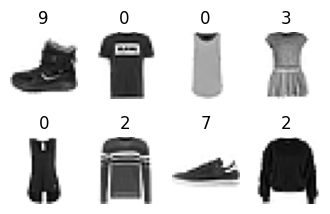

In [1]:
import matplotlib as mpl
from datasets import load_dataset
from genaibook.core import show_images

mpl.rcParams["image.cmap"] = "gray_r"

fashion_mnist = load_dataset("zalando-datasets/fashion_mnist")

samples = fashion_mnist["train"][:8]
clothes = samples["image"]
classes = samples["label"]

show_images(clothes, titles=classes, figsize=(4, 2.5))

클래스 0은 티셔츠, 2는 스웨터, 9는 부츠에 해당한다. ch4와 유사하게 데이터셋과 dataLoader를 준비하되, 클래스 정보도 입력으로 포함한다는 차이가 있다. ch4와 달리, 원본 이미지 입력(28 * 28 pixel)을 32 * 32로 패딩할 것이다. 이는 원본 이미지 품질을 보존하여 U-Net이 더 높은 품질의 예측을 하는데 도움이 된다.

In [2]:
import torch
from torchvision import transforms

preprocess = transforms.Compose(
    [
        transforms.RandomHorizontalFlip(), # Data augmentation
        transforms.ToTensor(), # To tensor(0, 1)
        transforms.Pad(2), # add 2 pixels to each side
        transforms.Normalize([0.5], [0.5]), # Maps to (-1, 1)
    ]
) # (1)

def transform(examples): #(2)
    images = [preprocess(image) for image in examples["image"]]
    return {"images": images, "labels": examples["label"]} #(3)

train_dataset = fashion_mnist["train"].with_transform(transform) #(4)
train_dataloader = torch.utils.data.DataLoader(
    train_dataset, batch_size=256, shuffle=True
) #(5)

1. 데이터셋의 이미지에 적용할 일련의 변환(증강, 텐서변환, 패딩, 정규화)을 정의한다. 
2. 변환을 사용해 이미지 배치를 처리한다. 
3. 처리된 이미지와 해당 레이블을 포함하는 dictionary를 반환한다. 
4. 데이터셋의 학습 분할을 로드한다. `with_transform()`을 사용하면 변환을 적용한 후 항목이 반환되도록 할 수 있다. 
5. 배치를 구성하고 데이터를 섞어주는 `Dataloader`를 생성하여 코드를 단순화한다. 

### 1.2 클래스 conditioning 모델 만들기

diffuser 라이브러리의 U-Net은 사용자 정의 conditioning 정보를 추가할 수 있다. 여기서는 ch4와 유사한 모델을 생성하지만 U-Net 생성자에 `num_class_embeds`인수를 추가한다. 이 인수는 클래스 레이블을 추가 조건으로 활용할 것임을 모델에 알린다. `fashion MNIST`에는 10개의 클래스가 있기애, `num_class_embeds=10`으로 설정한다. 

In [3]:
from diffusers import UNet2DModel

model = UNet2DModel(
    in_channels=1, # 흑백 이미지 1개 채널
    out_channels=1,
    sample_size=32,
    block_out_channels=(32, 64, 128, 256),
    num_class_embeds=10,
)

이 모델로 예측하려면 클래스 레이블을 추가 입력으로 `forward()` 메서드에 전달해야 한다. 

In [4]:
x = torch.randn((1, 1, 32, 32))
with torch.inference_mode():
    out = model(x, timestep=7, class_labels=torch.tensor([2])).sample
out.shape

torch.Size([1, 1, 32, 32])

이때 모델에 타입스텝도 condition으로 전달된다는 점이 중요하다. ch4에서 사용한 모델도 conditioning diffusion model로 간주할 수 있다. 확산 과정에서 현재 진행 단계를 모델이 알 수 있다면 더 현실적인 이미지를 생성하는데 도움이 되므로 타입 스텝을 조건으로 포함한다. 

내부적으로 타임스텝과 클래스 레이블은 모델이 순전파 과정에서 활용하는 임베당으로 변환된다. U-Net 전체에서 여러 단계에 걸쳐 이러한 임베딩이 사용되며, 각 층의 채널 수와 일치하는 차원으로 투영된 후 해당 층의 출력에 추가된다. 즉, U-Net의 모든 블록에서 조건부 정보가 사용되도록 하여 모델이 이를 효과적으로 학습하도록 한다.    
임베딩은 타임스텝고 클래스 레이블 같은 조건부 정보를 간결하고 밀접한 형태로 표현하므로 diffusion model에서 매우 효과적이다. 또한 연속된 값(e.g. timestep), 범주형 데이터(e.g. class labels), 텍스트 데이터(e.g. prompt) 등 다양한 유형의 조건부 입력을 유연하게 처리한다. 

### 1.3 모델 학습하기

노이즈 추가 기법은 ch4에서 사용한 나비 이미지뿐만 아니라 흑백 이미지에도 동일하게 적용할 수 있다. 노이징 타임스텝을 증가시키면서 노이즈가 모델 출력에 미치는 영향을 살펴보자. 

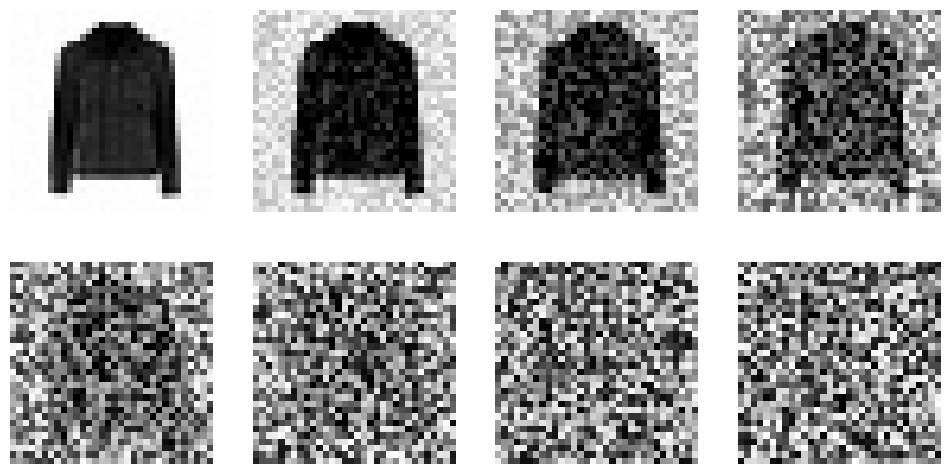

In [5]:
from diffusers import DDPMScheduler

scheduler = DDPMScheduler(
    num_train_timesteps=1000, beta_start=0.001, beta_end=0.02
)
timesteps = torch.linspace(0, 999, 8).long()
batch = next(iter(train_dataloader))
#데이터셋에서 8개의 이미지를 불러와서, 점진적으로 더 많은 노이즈 추가. 
x = batch["images"][0].expand([8, 1, 32, 32])
noise = torch.rand_like(x)
noised_x = scheduler.add_noise(x, noise, timesteps)
show_images((noised_x *0.5 + 0.5).clip(0, 1))

학습 루프는 ch4와 거의 동일하지만, 이번에는 conditioning을 위해 클래스 레이블을 전달한다. 이는 모델에 추가 정보를 제공하는 것일 뿐, loss function을 정의하는 방식과는 무관하다. 또한 모델 학습 중 진행 상황을 표시하는데 `tqdm`을 사용할 것이다.

이제 학습을 시작해보자. 코드는 다음을 수행한다: 
1. 이미지 묶음과 해당하는 레이블을 불러온다(`train_dataloader`와 `tqdm`을 사용해 반복).
2. 각 시간 단계에 따라 이미지에 노이즈를 추가한다(`scheduler.add_noise()` 을 사용).
3. 노이즈 이미지를 모델에 넣고 조건을 위한 클래스 레이블과 함께 사용한다(`model()`).
4. Loss를 계산한다. 
5. Loss를 backprop하고 optimizer로 model weight를 업데이트한다. 

In [11]:
from torch.nn import functional as F
from tqdm import tqdm
from genaibook.core import get_device

# 스케줄러 초기화
scheduler = DDPMScheduler(
    num_train_timesteps=1000, beta_start=0.0001, beta_end=0.02
)

num_epochs = 25
lr = 3e-4
optimizer = torch.optim.AdamW(model.parameters(), lr=lr, eps=1e-5)
losses = []  # 나중에 시각화하기 위한 손실값 저장소
device = get_device()
model = model.to(device)

# 모델 학습(시간이 많이 걸림)
for epoch in (progress := tqdm(range(num_epochs))):
    for step, batch in (
        inner := tqdm(
            enumerate(train_dataloader),
            position=0,
            leave=True,
            total=len(train_dataloader),
        )
    ):
        # 입력 이미지와 클래스 로드
        clean_images = batch["images"].to(device)
        class_labels = batch["labels"].to(device)
        # 이미지에 추가할 노이즈 샘플링
        noise = torch.randn(clean_images.shape).to(device)
        # 각 이미지에 대한 무작위 타임스텝 샘플링
        timesteps = torch.randint(
            0,
            scheduler.config.num_train_timesteps,
            (clean_images.shape[0],),
            device=device,
        ).long()
        # 각 타임스텝의 노이즈 크기에 따라 깨끗한 이미지에 노이즈 추가
        noisy_images = scheduler.add_noise(clean_images, noise, timesteps)
        # 노이즈에 대한 모델 예측 가져오기
        # class_labels 사용에 주목
        noise_pred = model(
            noisy_images,
            timesteps,
            class_labels=class_labels,
            return_dict=False,
        )[0]
        # 예측과 실제 노이즈 비교
        loss = F.mse_loss(noise_pred, noise)
        # 손실 표시 업데이트
        inner.set_postfix(loss=f"{loss.cpu().item():.3f}")
        # 나중에 시각화를 위해 손실 저장
        losses.append(loss.item())
        # 역전파 및 최적화
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()

100%|██████████| 25/25 [1:23:47<00:00, 201.11s/it]


In [17]:
model.save_pretrained("/content/fashion_ddpm/model")
scheduler.save_pretrained("/content/fashion_ddpm/scheduler")

print("저장 완료")

저장 완료


학습이 완료되면 training loss를 그래프로 표시해 모델의 성능을 확인할 수 있다. 

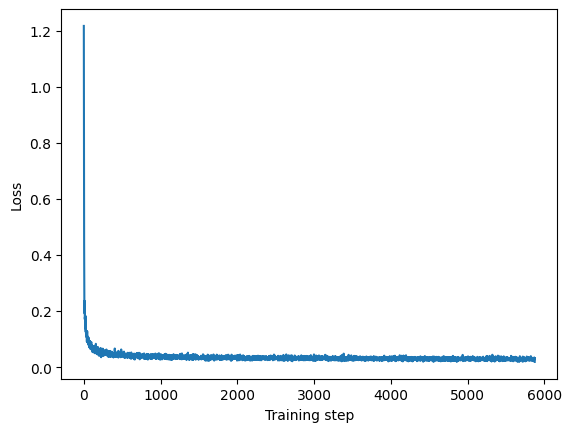

In [14]:
import matplotlib.pyplot as plt

plt.plot(losses)
plt.xlabel("Training step")
plt.ylabel("Loss")
plt.show()

### 1.4 샘플링

이제 예측할 때 두 가지 입력(이미지와 클래스 레이블)을 받는 모델을 만들었다. 무작위 노이즈로 시작한 후 반복해서 디노이징하며 원하는 클래스 레이블을 전달하여 샘플을 생성할 수 있다. 

In [15]:
def generate_from_class(class_to_generate, n_samples=8):
    sample = torch.randn(n_samples, 1, 32, 32).to(device)
    class_labels = [class_to_generate] * n_samples
    class_labels = torch.tensor(class_labels).to(device)

    for _, t in tqdm(enumerate(scheduler.timesteps)):
        # 모델 예측 가져오기
        with torch.inference_mode():
            noise_pred = model(
                sample, t, class_labels=class_labels
            ).sample

        # 단계로 샘플 업데이트
        sample = scheduler.step(noise_pred, t, sample).prev_sample

    return sample.clip(-1, 1) * 0.5 + 0.5

이미지를 몇 개 생성해보자.

1000it [00:25, 38.77it/s]
1000it [00:26, 38.29it/s]
1000it [00:26, 38.04it/s]


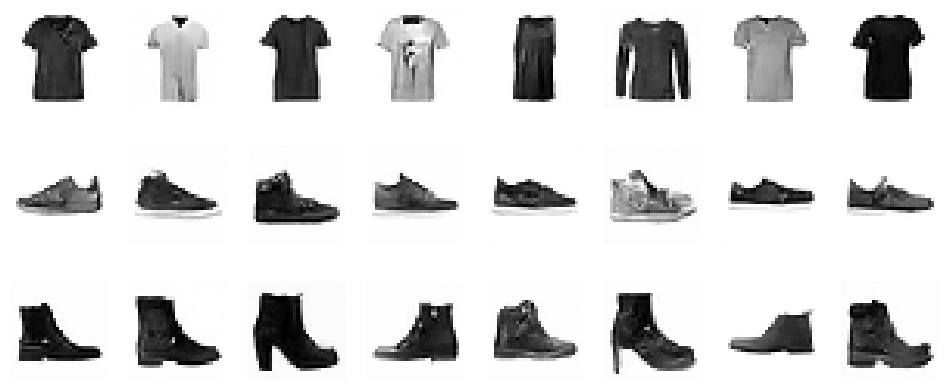

In [16]:
model.eval()
fig, axes = plt.subplots(3, 8, figsize=(12, 5))

for row, cls in enumerate([0, 7, 9]):
    images = generate_from_class(cls, n_samples=8).detach().cpu()
    for ax, image in zip(axes[row], images):
        ax.imshow(image.squeeze(), cmap="gray_r")
        ax.axis("off")


생성한 이미지에는 여전히 노이즈가 남아있다. 모델 아키텍쳐를 탐색하고, 하이퍼 파라미터로 튜닝하고, 더 오래 학습시키면 결과가 개선될 수 있다. 이로써 모델은 부츠를 볼 때 숫자 9와 함께 보는데 익숙하다. 이미지를 생성하고 9를 제공하라고 요청하면 부츠로 모델이 응답한다. 

## 2. 효율성을 높이는 Latent Diffusion

conditioning 모델을 학습시킬 수 있으니, 이제 단순히 규모를 확장하고 클래스 레이블 대신 텍스트에 conditioning을 하면 될까? 그렇지 않다. 이미지 크기가 증가함에 따라 이러한 이미지로 작업하는 데 필요한 컴퓨팅 자원도 증가한다. 이는 특히 self-attention에서 두드러지는데, 입력 수가 증가함에 다라 연산량이 o($n^2$)으로 증가한다. 128 * 128 이미지는 64 * 64 이미지보다 픽셀이 $4\times$ 이기에, self-attention layer에서 필요한 메모리와 자원이 16배 증가한다. 이는 고해상도 이미지를 생성하려 할 때 문제가 된다. 

Latent Diffusion은 별도의 VAE를 사용해 이 문제를 완화하려고 한다. 
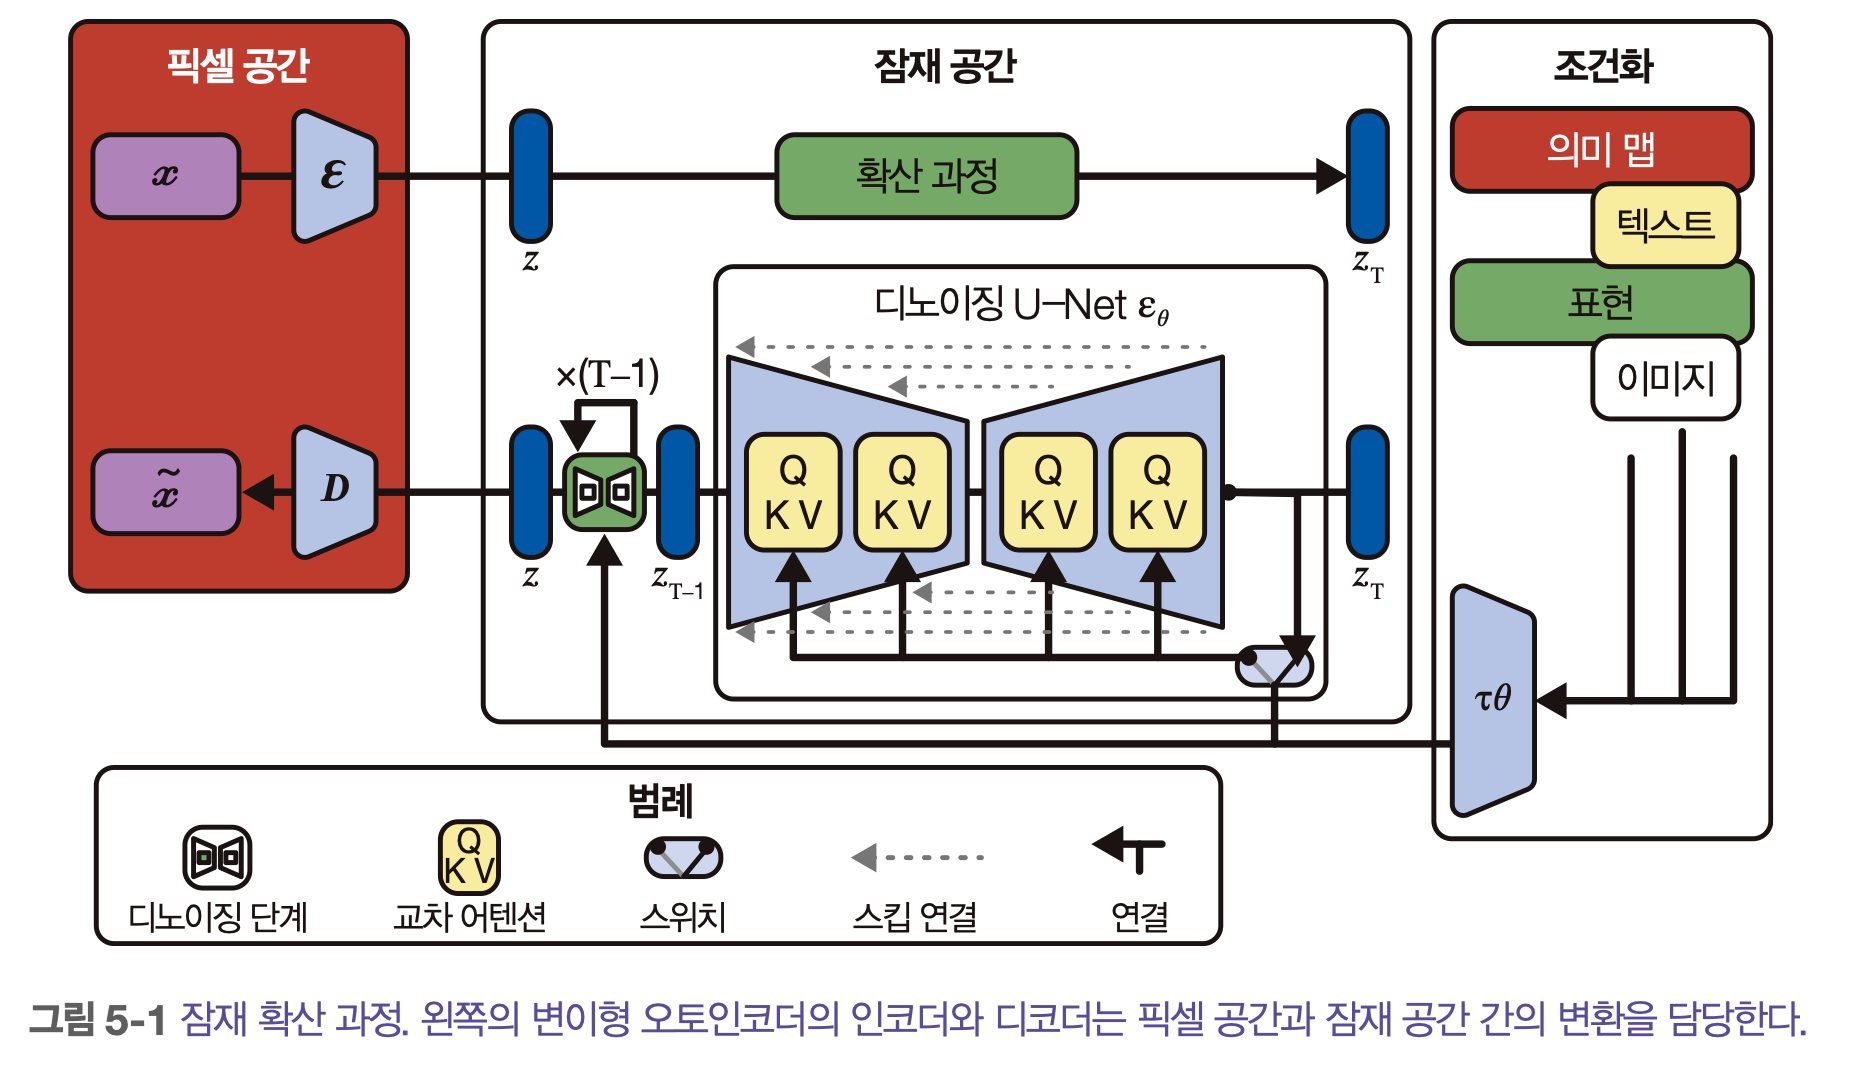
ch2에서 보았듯이, **VAE는 이미지를 더 작은 공간 차원으로 압축할 수 있다. 이론적 근거는 이미지가 중복 정보를 많이 포함하는 경향이 있다는 점이다.** 충분한 학습 데이터가 있다면 VAE는 입력 이미지의 훨씬 작은 표현을 생성하고 이 작은 latent representation을 기반으로 높은 정확도로 이미지를 재구성하는 방법을 학습할 수 있다. `Stable Diffusion`에 사용된 VAE는 3채널 이미지를 입력으로 받아 공간 차원마다 8배 감소 요소를 가진 4채널 latent representation을 생성한다. 512 * 512 입력 이미지($3 \times 512 \times 512 = 796,432$개의 값)는 $4 \times 64 \times 64 = 16,384$개의 값으로 압축된다. 

전체 해상도 이미지 대신 더 작은 latent representation에 확산 과정을 적용하면, 더 작은 이미지를 사용할 떄의 장점을 얻을 수 있다. 예를 들어 메모리 사용이 줄어들고, U-Net에 필요한 층 수가 감소하여, 생성 시간이 빨라진다. 결과물을 고해상도 이미지로 디코딩할 준비가 되면 다시 높은 해상도의 이미지를 얻을 수 있다. 이러한 접근 방식은 모델 학습과 실행 비용을 크게 절감한다. Latent Diffusion Models(https://arxiv.org/pdf/2112.10752)에서는 Segmentation map, class label, text를 조건으로 하는 모델을 학습시켜 이 기법이 효과를 입증했다. 그 결과로 저자들과 LAION, StabilityAI, RunwayML, ElutheraAI와 같은 파트너 간 추가 협업이 이루어져 더 고성능의 모델인 Stable Diffusion이 탄생했다. 

## 3. Stable Diffusion 구성 요소 심층 분석

`Stable Diffusion`은 텍스트 프롬프트에 조건화된 이미지를 생성할 수 있는 Latent Diffusion Model이다. 또한 이미지 수정과 같은 다른 여러 작업에도 사용할 수 있다. 이는 디퓨저와 같은 라이브러리에도 잘 지원되어 사용자 친화적인 파이프라인을 통해 stable diffusion으로 이미지를 샘플링할 수 있다. 

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

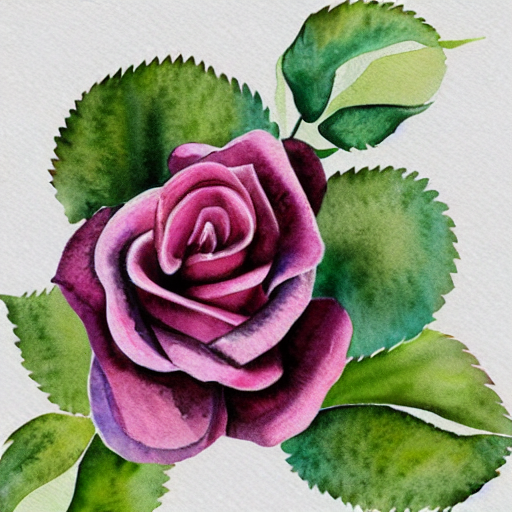

In [18]:
from diffusers import StableDiffusionPipeline

pipe = StableDiffusionPipeline.from_pretrained(
    "stable-diffusion-v1-5/stable-diffusion-v1-5",
    torch_dtype=torch.float16,
    variant="fp16",
).to(device)

pipe("Watercolor illustration of a rose").images[0]

### 3.1 Text Encoder

Stable Diffusion이 text를 이해하는지 살펴보자. 앞서 U-Net에 추가 정보를 제공하면 생상되는 이미지의 종류를 어느 정도 제어할 수 있다고 하였다. 이미지의 노이즈가 있는 버전이 주어지면, 모델은 클래스 레이블과 같은 추가 단서를 기반으로 디노이징된 버전을 예측하는 작업을 진행한다. Stable Diffusion에서 추가 단서는 텍스트 프롬프트다. 추론 시 생성하고 싶은 이미지의 설명을 제공하고 순수 노이즈를 입력하면 모델은 무작위 입력을 캡션과 일치하는 무언가로 최대한 디노이징하려고 시도한다. 

그러려면 텍스트가 설명하는 내용에 관한 관련 정보를 담은 텍스트의 수치 표현을 생성해야 한다. 이때 입력 문자열을 텍스트 임베딩으로 변환하는 text encoder를 사용한다. 이 임베딩은 다음과 같이 timestep과 noise가 있는 latent variable과 함께 U-Net에 입력된다. 
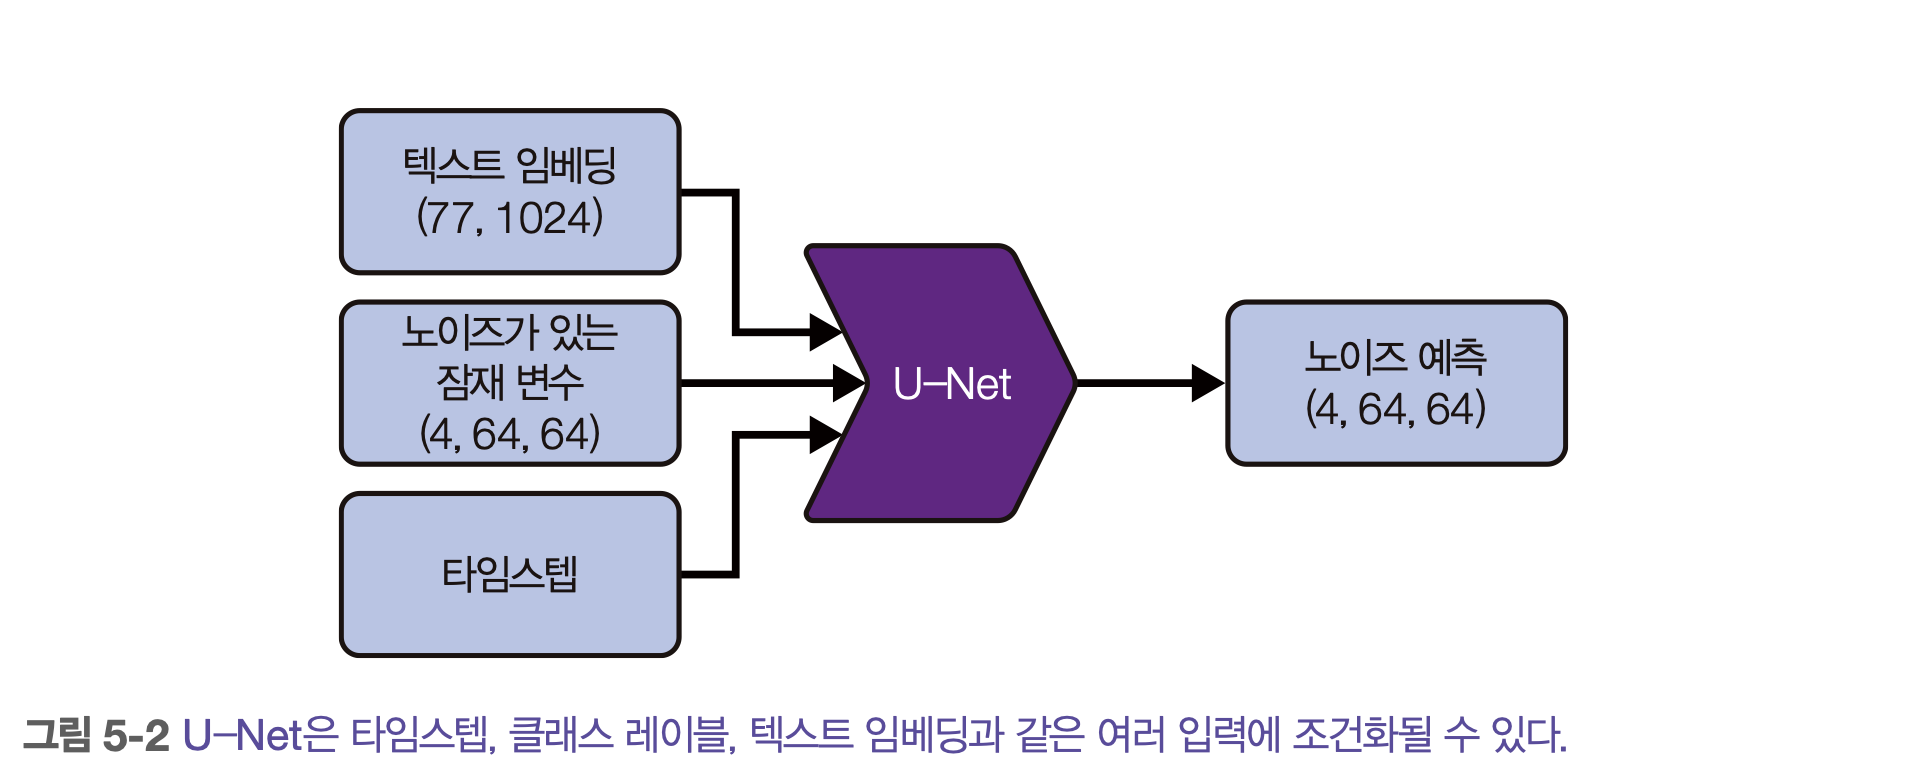
Stable diffusion은 ch3에서 소개한 `CLIP` 기반의 pretrained transformer를 활용해 이를 수행한다. text encoder는 token sequence를 입력받아 각 token에 대한 vector를 생성하는 transformer model이다. Stable Diffusion의 초기 버전(1~1.5)에서는 openAI의 원본 CLIP을 사용했고 text encoder는 768 차원의 벡터로 매핑했다. CLIP의 원본 데이터셋이 알려지지 않았으므로 커뮤니티는 `OpenCLIP`이라는 오픈 소스 버전을 학습시켰다. Stable Diffusion2는 OpenCLIP의 텍스트 인코더를 사용하며, 각 토큰에 대해 1024 차원의 벡터를 생성한다. 

모든 토큰의 벡터를 단일 표현으로 결합하는 대신, 이를 별도로 유지하고 U-Net을 위한 조건으로 사용한다. 이로써 U-Net은 프롬프트의 전체적인 의미뿐만 아니라 각 토큰의 정보를 개별적으로 사용할 수 있다. `CLIP` 모델의 내부 표현에서 이러한 텍스트 임베딩을 추출하므로, 이를 **encoder hidden states(인코더 은닉 상태)** 라고 부르기도 한다. text encoder가 내부적으로 어떻게 작동하는지 더 자세히 살펴보자. 

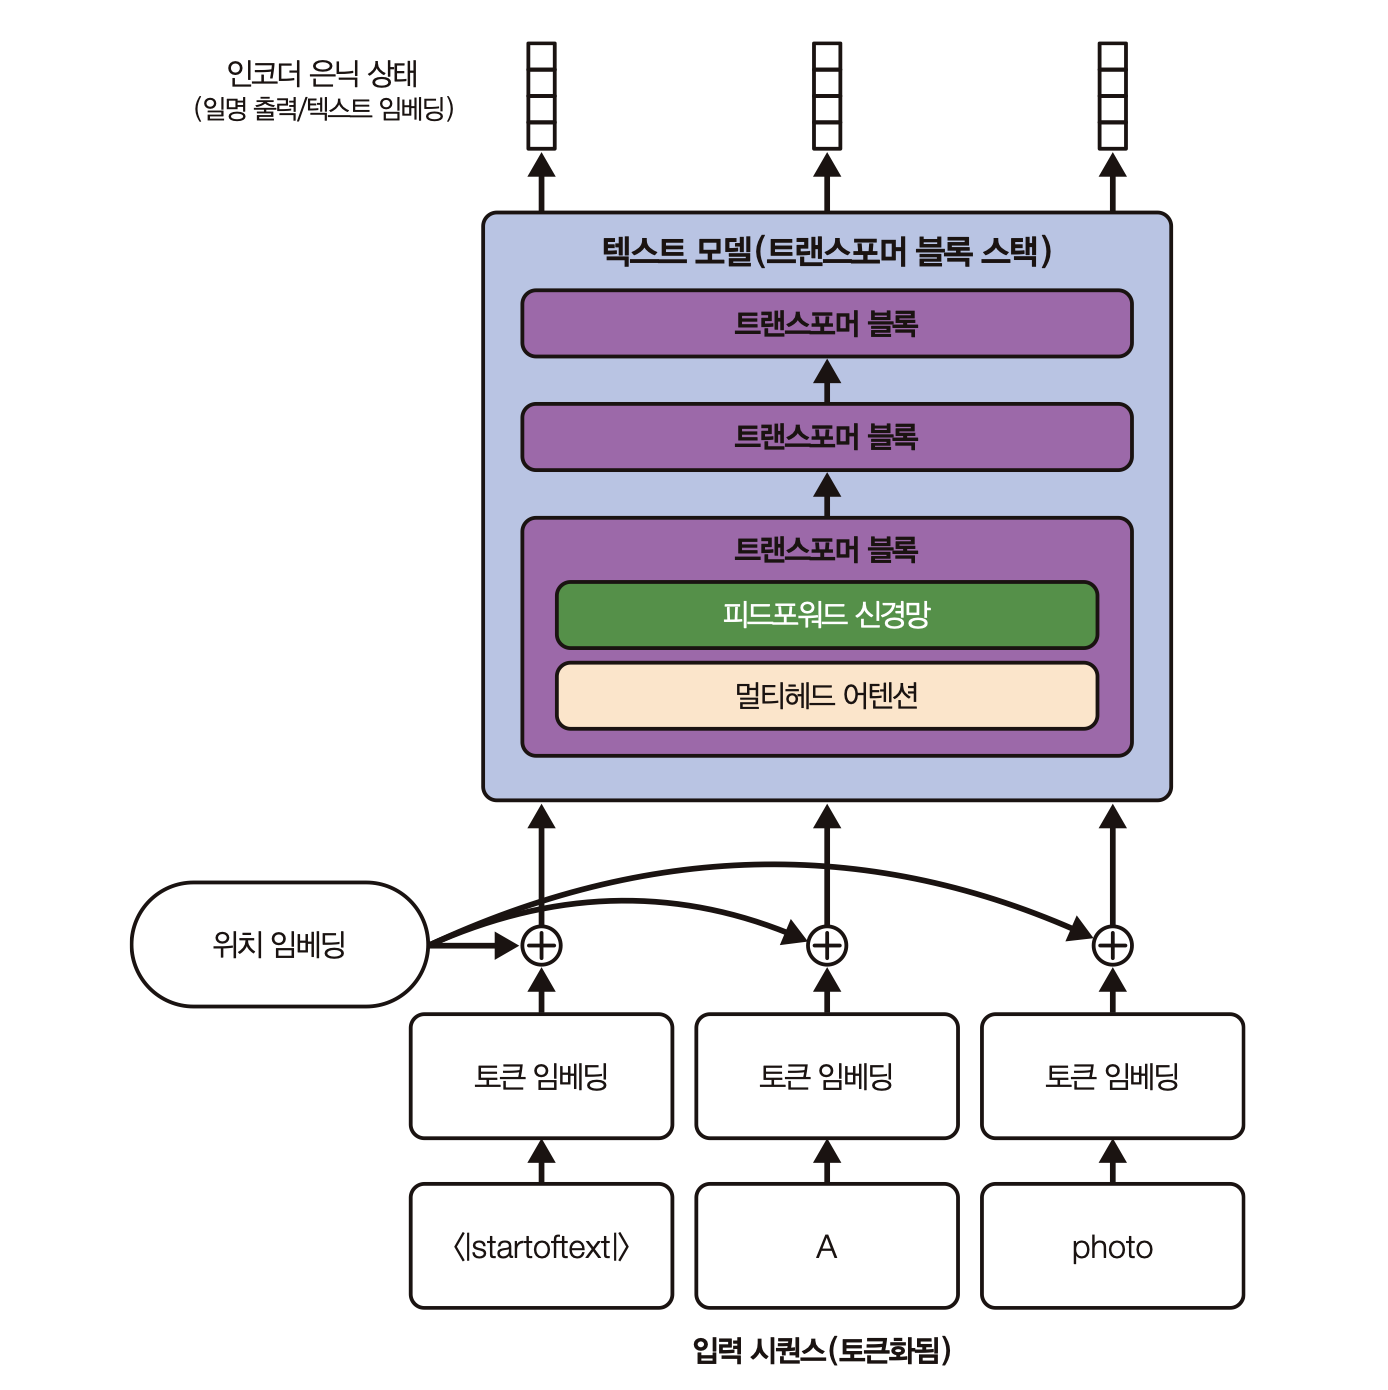
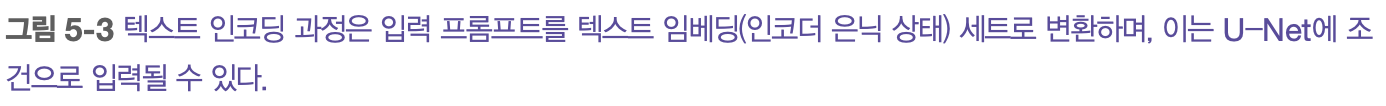
텍스트를 인코딩하는 첫 번째 단계는 토큰화를 수행하는 것이다. 이는 ch2에서 배운대로 문자 시퀀스를 숫자 시퀀스로 변환한다. 다음 예제에서는 stable diffusion의 tokenizer를 사용해 구문을 토큰화하는 방법을 보여준다. 프롬프트의 각 토큰에는 고유한 토큰 번호가 할당된다(e.g. photographer는 tokenizer vocabulary에서 8853). 또한 문장이 어디서 끝나는지와 같은 추가 context를 제공하는 특수 토큰도 있다. 

In [ ]:
prompt = "A photograph of a puppy"
text_input = pipe.tokenizer(prompt, return_tensors="pt")

for t in text_input["input_ids"][0]:
    token_id = t.item()
    print(token_id, pipe.tokenizer.convert_ids_to_tokens(token_id))
    # 현재 토크나이저의 decoder는 딕셔너리가 아니어서 .get()을 사용할 수 없음. convert_ids_to_tokens()로 대체. 

49406 <|startoftext|>
320 a</w>
8853 photograph</w>
539 of</w>
320 a</w>
6829 puppy</w>
49407 <|endoftext|>


텍스트가 토큰화되면, text encoder를 통과시켜 U-Net에 공급될 최종 텍스트 임베딩을 얻을 수 있다. 

In [21]:
text_embeddings = pipe.text_encoder(text_input.input_ids.to(device))[0]
print("Text embeddings shape:", text_embeddings.shape)

Text embeddings shape: torch.Size([1, 7, 768])


### 3.2 VAE

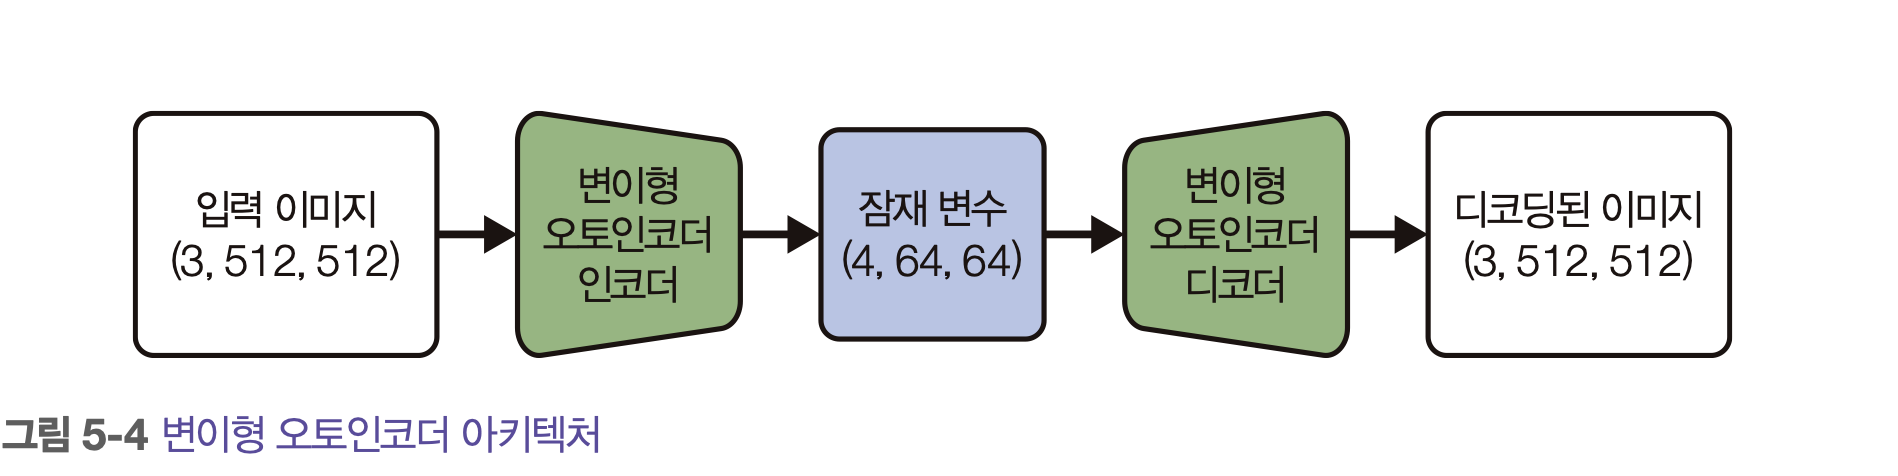
VAE는 이미지를 더 작은 latent representation으로 압축하고 다시 재구성하는 역할을 한다. 위 그림에 표시된 VAE는 Stable Diffusion 모델의 중요한 구성 요소이다. 이외에도 일반적인 reconstruction loss와 KL divergeance외에도 추가적인 특징이 있다. VAE는 모델이 현실적인 세부 사항과 텍스처를 생성하는 데 도움이 되는 ** patch-based discriminator loss(패치 기반 판별자 손실) ** 을 사용한다. 이는 이전 VAE에서 흔히 나타난 흐릿한 출력을 방지하는데 도움이 된다. Text encoder와 마찬가지로 VAE도 보통 별도로 학습되며 Diffusion model 학습과 샘플링 과정에서 고정된 구성 요소로 사용된다. 

이미지를 불러오고 VAE로 압축 및 압축 해제한 후 어떻게 보이는지 확인해보자. 우선 원본 이미지를 살펴보면 다음과 같다. 

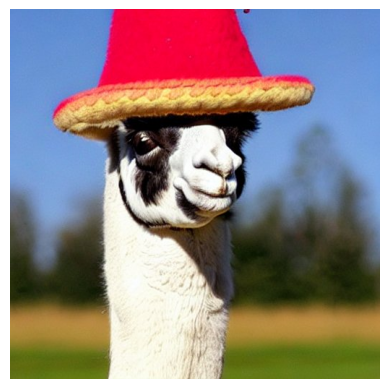

In [22]:
from genaibook.core import load_image, show_image, SampleURL

im = load_image(
    SampleURL.LlamaExample,
    size=(512, 512),
)
show_image(im);

이제 이미지를 VAE에 통과시켜 보자. 

In [23]:
with torch.inference_mode():
    # 이미지 처리
    tensor_im = transforms.ToTensor()(im).unsqueeze(0).to(device) * 2 - 1  #(1)
    tensor_im = tensor_im.half()  #(2)

    # 이미지 인코딩
    latent = pipe.vae.encode(tensor_im)  #(3)

    # 잠재 분포에서 샘플링
    latents = latent.latent_dist.sample()  #(4)
    latents = latents * 0.18215  #(5)

latents.shape

torch.Size([1, 4, 64, 64])

1. 이미지는 VAE의 입력 예상에 맞게 변환된다. 우선 `transforms.ToTensor()`로 텐서로 만들어 [0, 1] 범위로 변환하고, `unsqueeze(0)`으로 차원을 추가하여 배치 크기 1로 만든다. 동시에 `*2 - 1` 연산을 통해 VAE 입력 범위인 [-1, 1]에 맞게 이미지를 정규화한다. 
2. `torch.float16` 정밀도로 파이프라인을 불러왔기 때문에 이미지를 `float32`에서 `float16`으로 변환한다. 
3. 이미지는 VAE의 인코더를 통과한다. VAE는 샘플링할 수 있는 분포를 출력한다. 
4. VAE의 encoder가 생성한 분포 객체에 접근하여 샘플을 생성할 수 있다. 
5. 잠재 벡터를 `0.18215`의 크기로 스케일링한다. Stable Diffusion 저자들은 Diffusion 과정 중 추가된 노이즈의 대략적인 스케일과 일치하도록 하기 위해서, 분산이 1에 가까운 latent space를 갖게 하기 위해 이러한 스케일링 요소를 도입하였다. 이는 `vae.config.scaling_factor`에서 접근할 수 있다. 

원본 이미지는, 512 * 512 크기의 3 채널 이미지(786,432)이다. VAE는 이 이미지를 64 * 64 크기의 4 채널 latent representation(16,384 개 값)으로 압축한다. Latent representation의 각 채널을 그래프로 표시할 수 있다. 

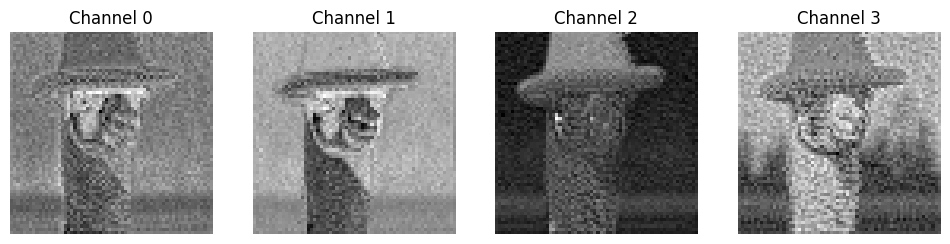

In [24]:
show_images(
    [l for l in latents[0]],
    titles=[f"Channel {i}" for i in range(latents.shape[1])],
    ncols=4,
)

이미지를 latent representation으로 인코딩하였으니, 이제 이를 다시 이미지로 디코딩할 수 있다. 이상적으로는 디코딩된 이미지가 원본 이미지와 동일해야 ㅎ나다. 하지만 실제로는 VAE가 일부 노이즈와 artifact(이미지 처리나 압축 과정에서 발생하는 원치 않는 시각적 왜곡이나 결함)를 발생시킬 수 있다. 디코딩된 이미지는 다음과 같이 확인할 수 있다. 

<Axes: >

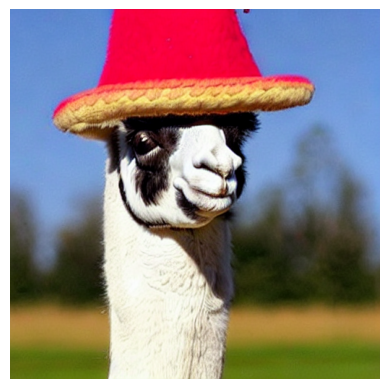

In [25]:
with torch.inference_mode():
    image = pipe.vae.decode(latents / 0.18215).sample
    # 화면 출력을 위해 [-1, 1] 범위 값을 [0, 1]으로 역정규화
image = (image / 2 + 0.5).clamp(0, 1)
show_image(image[0].float())

처음부터 이미지를 생성할 때는 시작점으로 무작위 latent variable set을 생성한다. 이 노이즈가 있는 latent variable을 반복 개선해 샘플을 생성하고, 최종 latent variable을 VAE의 디코더를 사용해 볼 수 있는 이미지로 디코딩한다.인코더는 기존 이미지에서 프로세스를 시작하고 싶을 때만 사용한다. 

### 3.3 U-Net

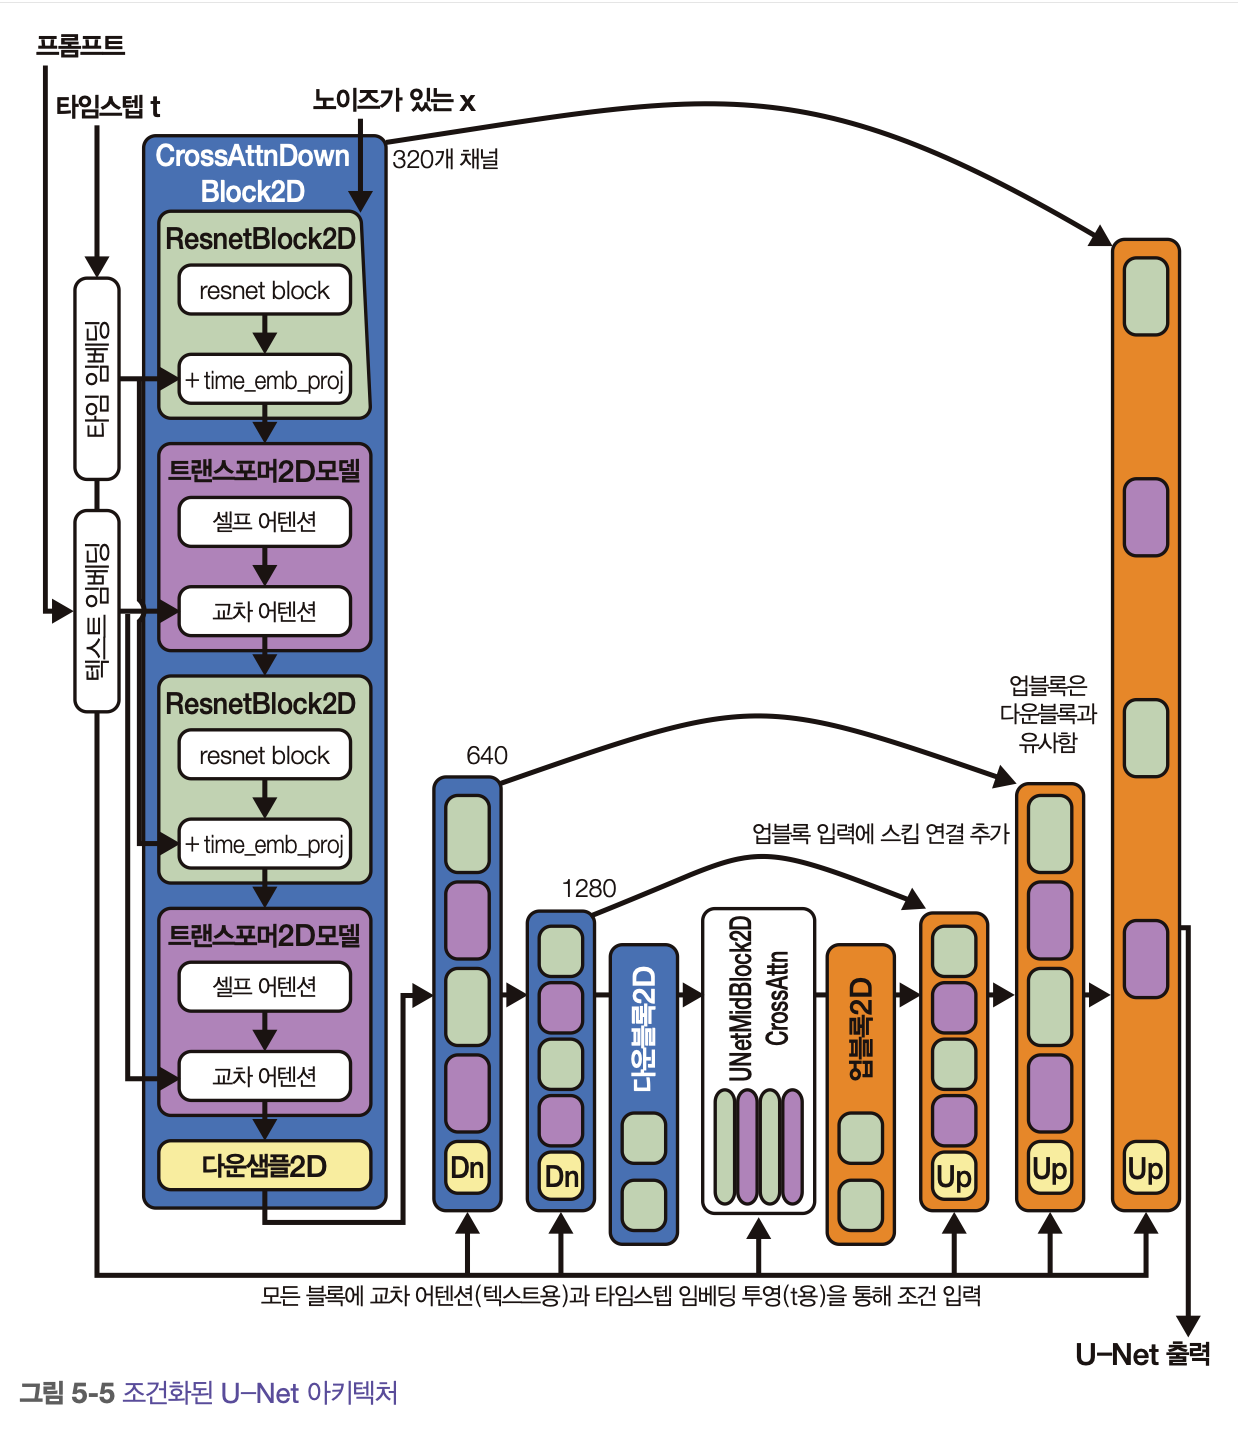
Stable Diffusion의 U-Net은 ch4의 이미지 생성에 사용한 것과 유사하지만, 3 채널 이미지대신 4채널 latent variable을 입력으로 받는다. 타임 스텝 임베딩은 이 장 조건부 클래스 예제처럼 제공되며, 여기에 텍스트 임베딩도 추가로 입력된다. cross-attention layer가 U-Net 전반에 분산되어 있어, 각 공간적 위치가 텍스트의 다양한 토큰에 attention을 수행할 수 있다. 이를 통해 prompt로부터 관련 정보를 가져올 수 있으며 위 그림과 같이 텍스트 및 타임스텝 조건이 U-Net에 입력된다.      
위 그림의 왼쪽에서 모델 입력을 확인할 수 있다. 노이즈가 있는 $\mathrm{x}$는 여기서 4 채널 latent variable이다. timestep과 prompt도 아키텍쳐의 다양한 지점에서 모델(임베딩 형태)에 제공된다. 이전의 모든 U-Net과 마찬가지로, 모델에는 입력을 다운 샘플링한 다음 원래 크기로 업샘플링하는 일련의 층이 있다. 신경망에는 모델이 이전 블록의 정보에 접근하도록 해 주는 스킵 연결도 있다. 

Stable Diffusion을 위한 U-Net 버전1과 2에는 약 8억 6천만(0.86B)의 매개변수가 있다. 가장 최근에 나온 Stable Diffusion XL(SDXL)의 U-Net에는 2.6B의 파라미터가 있으며, 추가 정보를 사용한다. 

### 3.4 Stable Diffusion XL

2023년 여름에 출시된 Stable Diffusion 버전이다. 이 모델은 다양한 개선 사항이 적용되었다.

- **더 나은 프롬프트 표현을 위한 더 큰 텍스트 인코더**: 두 개의 인코더 출력을 사용하여 임베딩을 연결한다.
- **모든 것을 조건으로 사용하기**: 타임 스텝(노이즈 양 정보 포함)과 텍스트 임베딩 외에도, SDXL은 다음과 같은 추가 요소를 조건으로 활용한다.
  - **원본 이미지 크기**: 학습 데이터의 약 40%를 차지하는 작은 이미지를 버리지 않고 업스케일링해 학습에 사용한다. 또한 모델은 수신 중인 이미지 크기에 관한 정보도 받는다. 이를 통해 모델은 업스케일링 artifact가 큰 이미지의 일부가 아님을 학습하고, 추론 중에 더 나은 품질을 생성하도록 한다.
  - **자르기 좌표**: 일반적으로 배치의 모든 이미지의 크기가 같아야 하므로 입력 이미지는 학습 중에 임의로 잘린다. 이때 이미지 주체의 일부가 잘리거나 텍스트 프롬프트에서 설명한 대상이 완전히 제거되는 등의 문제가 발생할 수 있다. 모델 학습 후에 자르기 좌표를 (0, 0)으로 설정하여 자르지 않은 이미지를 요청하면 모델이 프레임 중앙에 주체를 배치할 가능성이 더 높아진다.
  - **목표 종횡비**: 정사각형 이미지로 초기 사전 학습을 진행한 후, SDXL은 다양한 **aspect ratio(종횡비)**로 finetuning되었으며, 원본 종횡비에 관한 정보가 또 다른 조건부 신호로 사용되었다. 다른 조건부 케이스와 마찬가지로, 이 덕분에 훨씬 더 다양한 생성이 가능해졌다.
- **더 높은 해상도**: SDXL은 1024 × 1024 픽셀 해상도의 이미지를 생성하도록 설계되었다(또는 대략 $1{,}024^2$ 픽셀 수의 비정사각형 이미지). 종횡비와 마찬가지로, 이 기능은 finetuning 단계에서 달성되었다.
- **약 세 배 더 커진 U-Net**: Cross-attention context가 조건부 정보량 증가를 수용하기 위해 더 커졌다.
- **개선된 VAE**: 기존 Stable Diffusion과 동일한 architecture를 사용하지만 더 큰 배치 크기로 학습되었으며, 가중치 업데이트에 exponential moving average를 사용한다(최근 데이터에 더 높은 가중치를 부여하는 평균 계산 방법으로, 모델 학습 시 가중치 업데이트를 안정화하는 데 사용).
- **정제기 모델**: 기본 모델 외에도 SDXL은 기본 모델과 동일한 latent space에서 작동하는 추가 **refiner(정제기)** 모델을 포함한다(기본 모델에서 생성된 이미지의 품질을 더 개선하는 추가 모델). **그러나 이 모델은 노이즈 스케줄의 첫 20% 동안만 고품질 이미지로 학습되었다.** 이는 적은 양의 노이즈가 있는 이미지를 가져와 고품질 텍스처와 세부 사항을 생성하는 데 특화되었음을 의미한다.

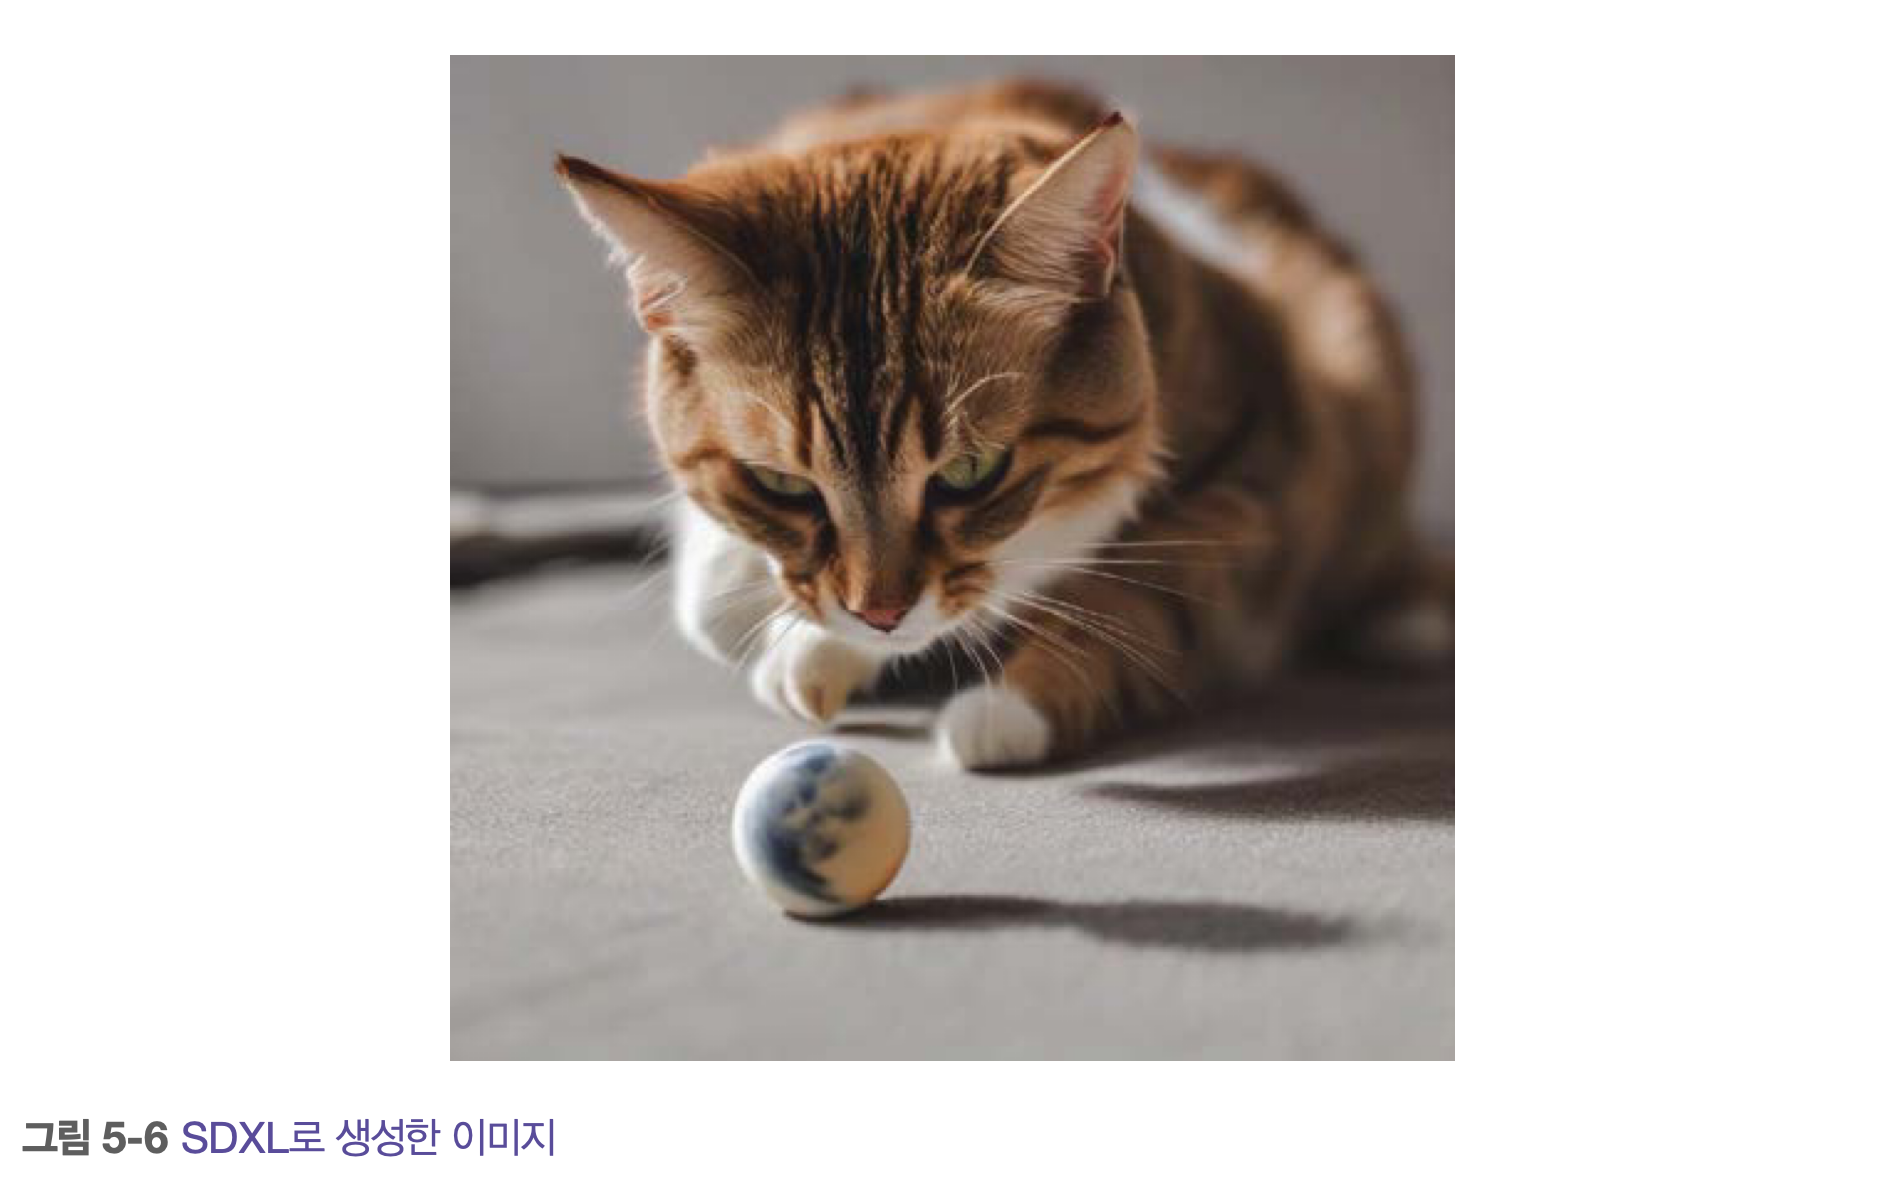
원본 Stable Diffusion이 오픈 소스 커뮤니티는 이미 이러한 기술 중 많은 부분을 연구했다. SDXL은 이러한 아이디어를 결합하여 위 그림과 같이 이미지 품질에서 눈에 띄는 향상을 달성하였으며 그 대가로 모델 실행 속도가 더 느려지고 메모리 사용량이 증가했다. 

### 3.5 FLUX, SD3, Video

Diffusion model 분야의 발전은 계속 빠르게 진행되고 있다. 2024년 6월에 스테빌리티 AI는 스테이블 디퓨전 3을 출시했고, 2024년 8월에는 블랙 포레스트 랩스(Black Forest Labs)가 플럭스 모델 제품군을 출시했다. 이 모델들의 원리는 이 장에서 배운 것과 같지만 몇 가지 중요한 차이점이 있다. 노이즈 제거 과정을 제어하는 정류된 흐름 매칭 스케줄러(rectified flow matching schedulers)(옮긴이: 기존 확산 모델의 스케줄러를 개선한 방식으로, 이미지 생성 과정을 더 효율적으로 조절한다.)라는 새로운 방식을 채택했으며 핵심 신경망 구조도 U-Net 대신 확산 트랜스포머(diffusion transformer)(https://arxiv.org/abs/2212.09748; U-Net 대신 트랜스포머 아키텍처를 사용하는 확산 모델의 변형이다.)를 사용하여 더 강력한 성능을 발휘한다.(더 자세한 정보는 패트릭 에서(Patrick Esser) 등이 작성한 「Scaling Rectified Flow Transformers for High-Resolution Image Synthesis」(https://arxiv.org/abs/2403.03206)를 참고.)

두 모델 제품군 모두 다양한 크기로 제공되며, 다양한 해상도를 지원하고, 프롬프트 이해와 텍스트 렌더링 기능이 개선되었다. 동일한 확산 트랜스포머 기반 아키텍처는 비디오 생성을 지원하도록 확장할 수 있다. CogVideoX(https://arxiv.org/abs/2408.06072)는 이러한 아이디어를 비디오 생성 공간에 적용하는 모델 제품군이다. 이러한 모델은 이 장에서 설명한 원리(특히 조건부)가 생성 모델의 행동을 제어하는 효과적인 범용 메커니즘이며 오픈 소스 배포가 연구 발전을 가속할 수 있음을 입증한다.

### 3.6 CFG: Classifier-Free Guidance, 분류기 없는 Guidance

텍스트 조건부를 최대한 유용하게 만들려는 많은 노력이 있었지만, 모델은 예측할 때 프롬프트보다 주로 노이즈가 있는 입력 이미지에 의존하는 경향이 있다. 많은 캡션이 관련 이미지와 느슨하게만 연관되기 때문에 모델이 설명에 너무 크게 의존하지 않는 법을 학습하는 것은 자연스러운 현상이다. **그러나 새 이미지를 생성할 때는 이런 현상이 문제가 된다. 모델이 프롬프트를 충분히 반영하지 않으면 요청한 설명과 관련성이 낮은 이미지가 생성될 수 있기 때문이다.**

이를 완화하고자 **가이던스(guidance)** 를 도입한다. 가이던스는 샘플링 과정에 더 많은 제어를 제공하는 모든 방법을 뜻한다. 적용할 수 있는 한 가지 방법은 특정 방향을 선호하도록 손실 함수를 수정하는 것이다. 예를 들어 특정 색상으로 생성을 편향시키고 싶다면, 평균적으로 목표 색상에서 얼마나 멀리 있는지 측정하도록 손실 함수를 변경할 수 있다. 또 다른 대안은 CLIP이나 분류기와 같이 결과를 평가하고 생성 과정의 일부로 이들의 손실 신호를 포함하는 모델을 사용하는 것이다. 예를 들어 CLIP을 사용해 프롬프트 텍스트와 생성된 이미지 임베딩 간의 차이를 비교하고 이 차이를 최소화하도록 확산 과정을 유도할 수 있다.

노이즈 예측을 `noise_pred = noise_pred_uncond + guidance_scale*(noise_pred_text - noise_pred_uncond)` 같이 수정해 guidance를 통합할 수 있다. 이 간단한 변화는 매우 효과적으로 작동하며 생성 결과를 훨씬 더 잘 제어하게 해준다. CFG 스케일 1, 2, 4, 12(출력 이미지의 왼쪽에서 오른쪽 순)로 "An oil painting of a collie in a top hat" 이라는 프롬프트의 결과를 확인해보자. 

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

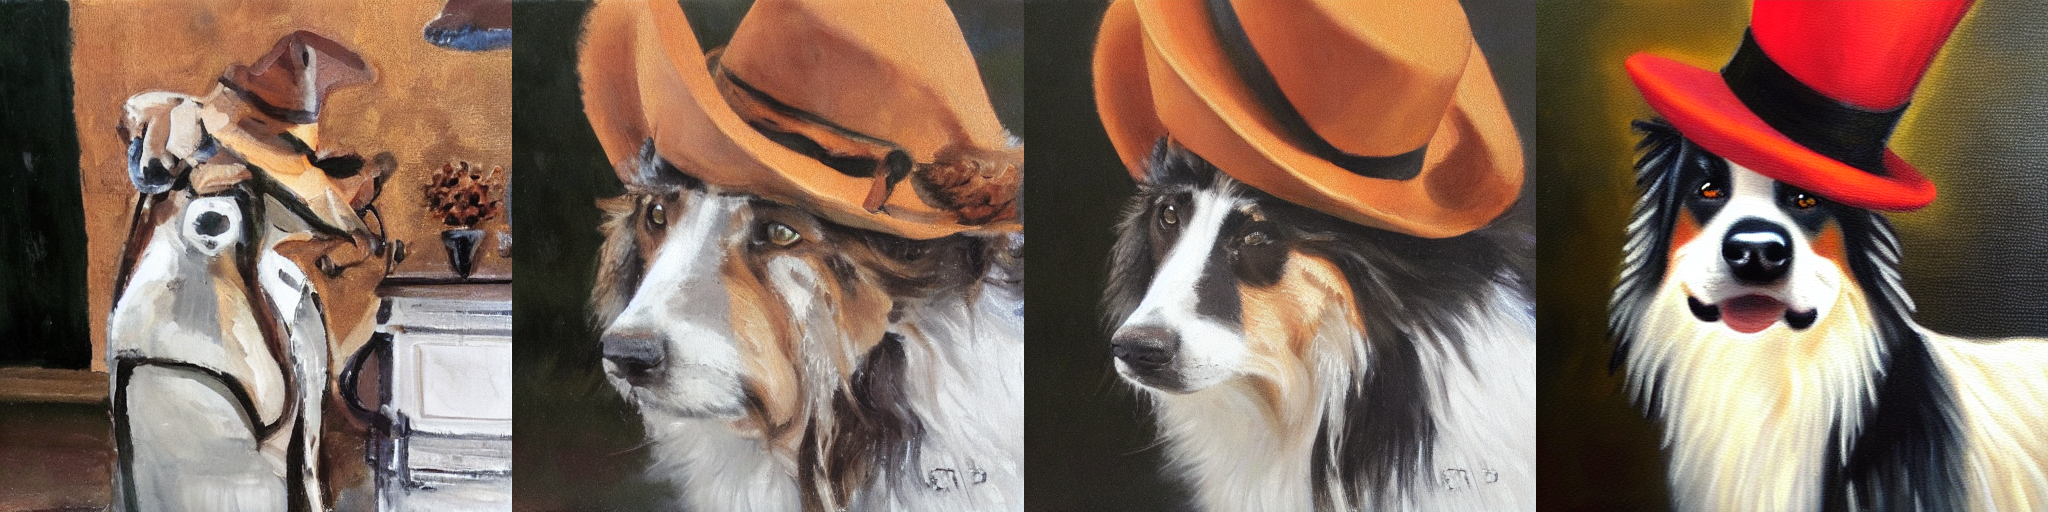

In [26]:
images = []
prompt = "An oil painting of a collie in a top hat"

for guidance_scale in [1, 2, 4, 12]:
    torch.manual_seed(0)
    image = pipe(prompt, guidance_scale=guidance_scale).images[0]
    images.append(image)

from genaibook.core import image_grid

image_grid(images, 1, 4)

결과물을 살펴보면 높은 값을 사용할수록 설명과 더 잘 일치하는 이미지가 생성되지만, 너무 높게 설정하면 이미지가 왜곡되기 시작할 수 있다. 구글의 이마젠 논문(https://arxiv.org/abs/2205.11487)에 따르면 예측 중인 값이 모델이 학습된 [-1, 1] 범위를 초과했기 때문이다. Diffusion model은 반복적으로 동작하므로 학습 중에 보지 못한 입력값을 처리해야 하며, 이 때문에 과도한 채도(**excessive saturation** , 확산 모델의 출력에서 색상이 비정상적으로 강렬해지는 현상으로, 생성된 이미지의 색채가 자연스러운 범위를 넘어서 과장되게 표현된다.), 포스터화(**posterization**, 연속된 색조의 이미지가 불연속적인 색상 단계로 변환되는 현상으로, 부드러운 그라데이션이 뚜렷한 경계가 있는 영역으로 나뉘게 된다.), 생성 실패가 발생할 수 있다. 연구자들은 **동적 임곗값 설정(dynamic thresholding** , diffusion model의 예측값이 학습된 범위를 초과할 때 이를 적절히 조정하여 생성 품질을 유지하는 기법이다.)이라는 방법을 제안해 값을 범위 내에 유지하고 높은 CFG 스케일에서 품질을 크게 향상했다.

## 4. 주석이 달린 샘플링 루프

각 구성 요소가 무엇을 하는지 알았으니, 이제 이들을 결합해 파이프라인에 의존하지 않고 이미지를 생성해볼 수 있다. 다음과 같은 설정을 사용한다. 

In [27]:
# 몇 가지 설정
prompt = [
    "Acrylic palette knife painting of a flower"
]  # 생성하려는 것
height = 512  # 스테이블 디퓨전의 기본 높이
width = 512  # 스테이블 디퓨전의 기본 너비
num_inference_steps = 30  # 디노이징 단계 수
guidance_scale = 7.5  # 분류기 없는 가이던스 스케일
seed = 42  # 난수 생성기의 시드

먼저 텍스트 프롬프트 "Acrylic palette knife painting of a flower"를 인코딩해야 한다. CFG를 수행할 계획이므로 두 가지 텍스트 임베딩 세트를 생성할 것이다. 하나는 프롬프트 임베딩을 포함하고 다른 하나는 비조건부 입력인 빈 문자열을 나타낸다. 여기서는 조건부가 없는 입력을 사용하겠지만 이 설정을 다양하게 활용할 수 있다. 예를 들어 다음과 같은 작업을 수행할 수 있다.
- **빈 문자열 대신 부정적 프롬프트 인코딩** : 부정적 프롬프트를 추가하면 모델이 특정 방향으로 가지 않도록 유도할 수 있다.
- **가중치가 다양한 여러 프롬프트 결합** : 프롬프트에 가중치 부여해 프롬프트의 특정 부분을 강조하거나 약화할 수 있다. 프롬프트 가중치 부여는 8장에서 더 자세히 알아볼 것이다.

텍스트 임베딩 생성을 다음과 같이 구현해보자. 

In [28]:
# 입력 토큰화
text_input = pipe.tokenizer(
    prompt,
    padding="max_length",  # 입력의 형태가 같아지도록 최대 길이로 패딩
    return_tensors="pt",
)

# 비조건부 입력(빈 문자열)에 대해서도 동일하게 수행
uncond_input = pipe.tokenizer(
    "",
    padding="max_length",
    return_tensors="pt",
)

# 두 임베딩을 텍스트 인코더를 통해 처리
with torch.inference_mode():
    text_embeddings = pipe.text_encoder(text_input.input_ids.to(device))[0]
    uncond_embeddings = pipe.text_encoder(uncond_input.input_ids.to(device))[0]

# 두 세트의 텍스트 임베딩을 연결
text_embeddings = torch.cat([uncond_embeddings, text_embeddings])

다음으로 무작위 초기 latent variable을 생성하고 원하는 추론 단계 수를 사용하도록 스케줄러를 설정한다. 

In [29]:
# 스케줄러 준비
pipe.scheduler.set_timesteps(num_inference_steps)

# 무작위 시작 잠재 변수 준비
latents = (
    torch.randn(
        (1, pipe.unet.config.in_channels, height // 8, width // 8),
    )
    .to(device)
    .half()
)
latents = latents * pipe.scheduler.init_noise_sigma

이제 샘플링 단계를 반복하면서 각 단계에서 모델 예측을 얻고 이를 사용해 latent variable을 업데이트 한다. 

In [30]:
for t in pipe.scheduler.timesteps:
    # 두 텍스트 임베딩(비조건부 및 조건부)과 일치하도록
    # 잠재 변수의 두 복사본을 생성
    latent_input = torch.cat([latents] * 2)
    latent_input = pipe.scheduler.scale_model_input(latent_input, t)

    # 비조건부 및 조건부 잠재 변수 모두에 대한 노이즈 잔차 예측
    with torch.inference_mode():
        noise_pred = pipe.unet(
            latent_input, t, encoder_hidden_states=text_embeddings
        ).sample

    # 예측을 비조건부 및 조건부 버전으로 분할
    noise_pred_uncond, noise_pred_text = noise_pred.chunk(2)

    # 분류기 없는 가이던스 수행
    noise_pred = noise_pred_uncond + guidance_scale * (
        noise_pred_text - noise_pred_uncond
    )

    # 다음 타임스텝을 위한 잠재 변수 업데이트
    latents = pipe.scheduler.step(noise_pred, t, latents).prev_sample

CFG 단계에 주목하자. 최종 노이즈 예측값은 `noise_pred_uncond + guidance_scale * (noise_pred_text - noise_pred_uncond)`로, 이는 예측을 비조건부 예측에서 멀어지게 하고 프롬프트에 기반한 예측 쪽으로 밀어낸다. 가이던스 스케일을 변경해 출력에 어떤 영향을 미치는지 확인해 보자.

루프가 끝날 쯤이면 잠재 변수는 프롬프트와 일치하는 그럴듯한 이미지를 나타내야 한다. 마지막 단계는 변이형 오토인코더를 사용해 잠재 변수를 이미지로 디코딩해 결과를 볼 수 있게 한다.

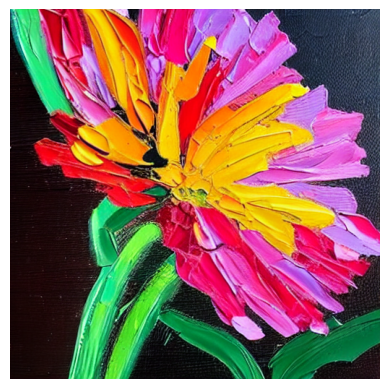

In [31]:
# 변이형 오토인코더로 이미지 잠재 변수를 스케일링하고 디코딩
latents = 1 / pipe.vae.config.scaling_factor * latents
with torch.inference_mode():
    image = pipe.vae.decode(latents).sample
image = (image / 2 + 0.5).clamp(0, 1)

show_image(image[0].float());

`StableDiffusionPipeline`의 소스 코드는 앞서 작성한 코드가 파이프라인이 사용하는 `call()` 메서드와 매우 유사하다. 

## 5. 오픈 데이터, 오픈 모델

`LAION-5B` 데이터셋은 50억 개가 넘는 이미지 URL과 각각의 관련 캡션(이미지-캡션 쌍)으로 구성된다. 이 데이터셋은 먼저 `CommonCrawl`에서 찾은 모든 이미지 URL을 모으고, CLIP을 사용해 텍스트와 이미지 간 유사성이 높은 이미지-캡션 쌍만 유지하는 방식으로 생성되었다.

누구나 자유롭게 사용할 수 있는 데이터셋의 필요성을 인식한 오픈 ML 커뮤니티가 `LAION-5B` 데이터셋을 만들어 공개했다. `LAION` 이니셔티브 이전에는 대형 기업의 소수 연구소만이 이미지-텍스트 쌍 데이터셋에 접근할 수 있었다. 이러한 조직은 데이터셋 세부 정보를 비공개로 유지하여 외부에서 결과를 검증하거나 복제할 수 없었다. `LAION`은 URL과 캡션 색인을 공개적으로 사용할 수 있게 함으로써 더 작은 커뮤니티와 기관이 모델을 학습시키고 연구를 수행할 수 있도록 도왔다. 이 덕분에 이전에는 불가능했던 연구와 개발이 가능해졌다.

첫 번째 latent diffusion model은 이런 모델에 속하며, `CompVis`에 의해 4억 개(0.4B)의 이미지-텍스트 쌍이 있는 `LAION` 데이터셋의 이전 버전으로 학습되었다. `LAION`으로 학습된 latent diffusion model이 공개되면서 고성능 텍스트-이미지 모델을 전체 연구 커뮤니티에서 처음으로 자유롭게 활용할 수 있게 되었다.

Latent diffusion의 성공은 이 접근 방식의 잠재력을 보여주었으며, 이는 후속 작업인 stable diffusion에서 실현되었다. Stable diffusion과 같은 모델을 학습하려면 상당한 GPU 시간이 필요했다. 무료로 제공된 `LAION` 데이터셋을 활용하더라도 소수만이 GPU 시간을 투자할 여력이 있었다. 따라서 모델 가중치와 코드의 공개가 큰 의미를 가지게 되었으며, 이는 비공개 모델과 비슷한 성능의 고품질 텍스트-이미지 모델이 모든 사람에게 공개된 최초 사례였다.
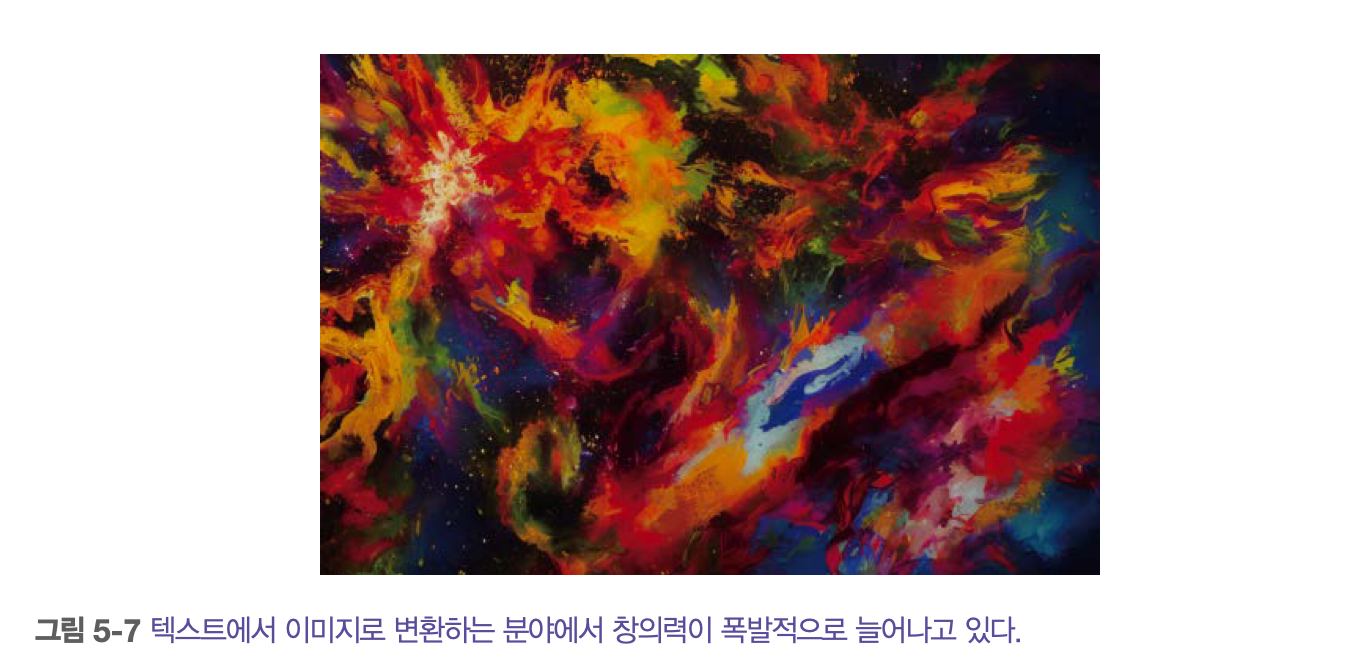
Stable Diffusion이 공개적으로 사용 가능해지면서 지난 몇 년간 많은 연구자와 개발자가 가장 먼저 선택하는 모델이 되었다. 수백 편의 논문에서 기본 모델에 새로운 기능을 추가하거나 속도와 품질을 개선하는 혁신적인 방법을 연구해 왔다. 또한 머신러닝 배경이 없는 다양한 커뮤니티에서도 창의적인 작업 과정을 개발하거나, 더 빠른 실행을 위해 최적화하는 등 모델을 다양하게 활용한다.    

수많은 스타트업이 이렇게 빠르게 발전하는 도구들을 제품에 통합하는 방법을 찾아 새로운 응용 프로그램 생태계를 형성했다. 

Stable Diffusion 도입 이후 몇 개월은 이러한 기술을 공개적으로 공유하는 영향력을 보여주었으며, 7장과 8장에서 살펴볼 많은 품질 개선과 커스터마이징 기법이 등장했다. stable diffusion은 당시 `DALL·E`와 미드저니(`Midjourney`) 같은 상업적 대안들과 품질 면에서 경쟁력이 있었고, 수천 명의 사람이 이를 개선하고 오픈 소스 기반 위에 구축하는 데 시간을 투자했다. 

`LAION-5B`는 stable diffusion 학습뿐만 아니라 다른 연구에도 많이 활용되었다. 그중 하나는 `LAION` 커뮤니티에서 주도한 OpenCLIP 프로젝트로, 최고 수준 오픈 소스 CLIP 모델을 학습시켜 원본 모델과 유사한 품질을 만들어냈다. 고품질의 오픈 소스 CLIP 모델은 이미지 검색과 제로샷 이미지 분류와 같은 많은 작업에 도움이 된다. 모델 학습에 사용된 데이터의 투명성은 모델 확장의 영향을 연구하고, 결과를 널리 재현하며, 연구를 더 접근 가능하게 했다.

### 5.1 `LAION-5B`의 한계점과 지원 중단

그러나 텍스트-이미지 생성 모델의 큰 성공과 이러한 모델을 기반으로 한 다운스트림 상업 응용 프로그램은 `LAION-5B` 데이터셋의 데이터 소스와 내용에 대한 우려를 제기했다.

데이터셋이 인터넷에서 크롤링된 이미지에 연결되는 링크로 구성되었으므로 사진, 예술 작품, 만화, 일러스트레이션과 같은 저작권이 있는 자료를 가리키는 수백만 개의 URL을 포함한다. 연구에 따르면 이러한 데이터셋에는 개인적으로 민감한 정보(예: 개인 식별이 가능한 의료 이미지)도 포함된다.

이러한 데이터셋을 사용해 생성형 AI 모델을 학습하면 모델이 사회적 편견을 강화하거나 악화하는 콘텐츠를 생성하거나 노골적인 성인용 콘텐츠를 제작하는 데 사용될 수 있다. 또한 이러한 모델은 학습 데이터와 매우 유사한 콘텐츠를 생성할 수 있으므로 저작권이 있는 자료와 극도로 유사한 콘텐츠 생성으로 이어질 수 있다. 그러나 이러한 오픈 모델은 오픈 데이터셋에서 학습되므로 이러한 편향과 문제가 되는 콘텐츠를 연구, 분석, 완화할 수 있다.

최근 연구에 따르면 `LAION-2B` 데이터셋은 인터넷에서 수집된 자료로, 폭력과 아동 안전과 관련된 명백한 불법 자료를 걸러내지 못해 데이터셋이 비활성화되었다.

### 5.2 대안

아동 안전을 이유로 `LAION` 데이터셋이 비활성화되면서 인터넷 수준의 이미지 스크래핑(internet-level scraping of images)이라는 유사한 방식을 따르는 개방형 데이터셋인 `COYO-700M`과 `DataComp-1B`가 그 공백을 채웠다. 이러한 데이터셋은 즉각 비활성화로 이어질 수 있는 콘텐츠를 포함하지는 않지만, 이전 절에서 언급한 편향, 저작권 자료, 개인 권리와 같은 문제를 여전히 안고 있다. 커먼캔버스(`CommonCanvas`)는 7천만 이미지-텍스트 쌍으로 이루어진 더 작은 규모의 데이터셋이지만, 오로지 공개적으로 크리에이티브 커먼즈 라이선스가 부여된 이미지만 포함한다.

### 5.3 공정하고 상업적인 사용

일부 국가에는 연구 용도의 저작권법 공정 이용 예외 규정이 있으며, 머신러닝 모델 학습 시 스크랩된 데이터를 사용하는 것과 관련해 법적으로 유리한 선례가 있는 국가도 있다. 그러나 이러한 자료로 학습된 연구 모델이 생성형 AI를 위해 상업적으로, 그리고 대규모로 사용될 때 어떤 일이 발생하는가? 이 복잡한 주제는 현재 미국과 유럽 여러 관할권의 법정에서 다루어지고 있으며 저작권법, 연구 응용에 대한 공정 사용, 개인 정보 보호, 창의적 직업에 대한 AI 도구의 경제적 영향 등과 관련된 측면들이 있다. 이러한 복잡한 문제에 대한 확실한 답을 내놓을 수는 없지만, 법적 불확실성 때문에 AI 모델 개발 연구자들과 오픈 소스 커뮤니티는 오픈 데이터셋 사용을 점차 꺼리게 되었다. 스테이블 디퓨전 XL은 모델 가중치가 오픈 소스로 공개되었지만 모델 학습에 사용된 데이터셋은 공개되지 않았다.

동의, 안전성, 라이선스 문제를 핵심적으로 고려한 새로운 대규모 텍스트-이미지 데이터셋을 구축하는 것은 연구자, 오픈 소스 커뮤니티, 상업적 응용 분야에 법적 확실성을 제공하는 중요한 자원이 될 것이다. 커먼캔버스 데이터셋은 이러한 접근 방식의 좋은 사례라고 할 수 있다.

## 6. `Gradio`로 Interactive ML demo 만들기 프로젝트

지금까지는 오픈 소스 라이브러리를 사용해 트랜스포머와 확산 모델을 실행하는 데 초점을 맞췄다. 이는 모델에 많은 유연성과 제어를 제공하지만 설정하고 실행하는 데 많은 작업이 필요하다. 현실적으로 대부분의 사람은 코딩 방법을 모르지만 모델과 그 기능을 살펴보는 데 관심이 있을 수 있다.

이 프로젝트에서는 Stable Diffusion을 사용해 텍스트 프롬프트에서 이미지를 생성하는 간단한 머신러닝 데모를 구축할 것이다. 데모를 활용해 모델을 더 많은 청중에게 쉽게 보여주고 작업과 연구를 더 접근 가능하게 할 수 있다.

생성형 AI 데모를 만드는 방법은 다양하다. HTML, 자바스크립트, CSS를 사용할 수 있지만 웹 개발 경험이 필요하며 간단한 과정이 아니다. **streamlit**(https://streamlit.io/)과 **gradio**(https://oreil.ly/bBo5a)를 사용하면 파이썬으로 인터랙티브한 머신러닝 데모를 쉽게 만들 수 있다. 이번 장에서는 아주 간단하고 최소한의 기능이 있는 gradio 라이브러리를 사용해 본다.

gradio 라이브러리는 파이썬 IDE, 주피터 노트북, 클라우드 환경(예: 구글 코랩, 허깅 페이스 스페이스(Hugging Face Spaces))에서도 실행할 수 있다. `Interface` 클래스를 사용하면 매우 쉽게 gradio 데모를 만들 수 있다. 이 클래스에는 세 가지 중요한 구성요소가 있다.

- **`inputs`**: 텍스트 프롬프트나 이미지와 같은 데모의 예상 입력 유형
- **`outputs`**: 생성된 이미지와 같은 데모의 예상 출력 유형
- **`fn`**: 사용자가 데모와 상호작용할 때 호출되는 함수. 트랜스포머나 디퓨저를 포함한 어떤 코드든 실행할 수 있다.

예시를 살펴보자.

In [32]:
import gradio as gr


def greet(name):
    return "Hello " + name


demo = gr.Interface(fn=greet, inputs="text", outputs="text")

demo.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://b17abe0ea9ac577aa8.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
